# Notebook 4b: Recurring Issues with Semantic Embeddings

Notebook 04 found recurring themes by clustering **TF-IDF + LSA** vectors, which measure *shared words*.
Notebook 02b showed that **BGE sentence embeddings** capture *meaning* much better for classification. Here we redo the clustering with BGE and ask:

1. What makes two tickets "similar" in each representation?
2. Do the recurring themes within each category change?
3. Does meaning-based clustering show anything new?

**Method:** same as notebook 04 (K-Means, number of groups chosen with the silhouette score, tickets as weights), only the embedding changes.
We recompute the LSA vectors exactly as notebook 04 did, so the two can be compared side by side.

**Requirements:** `sentence-transformers` (same as notebook 02b).

In [1]:
import os
os.environ.update(HF_HUB_DISABLE_PROGRESS_BARS="1", TRANSFORMERS_VERBOSITY="error", TQDM_DISABLE="1")
import sys
import logging
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
logging.disable(logging.WARNING)   # hide torch / Hugging Face start-up notices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.manifold import TSNE
from sentence_transformers import SentenceTransformer

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

TEXT, TARGET, SEED = config.TEXT, config.TARGET, config.SEED
FIG = config.FIGURES
BGE = "BAAI/bge-base-en-v1.5"

tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv", parse_dates=["created_at"])
unique = tickets.groupby([TEXT, TARGET]).size().rename("tickets").reset_index()

# BGE embeddings (768 numbers per sentence, unit length)
bge = SentenceTransformer(BGE).encode(unique[TEXT].tolist(), normalize_embeddings=True, show_progress_bar=False)

# LSA embeddings exactly as in notebook 04 (also used to name themes by their top words)
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(unique[TEXT])
terms = tfidf.get_feature_names_out()
lsa = normalize(TruncatedSVD(n_components=30, random_state=SEED).fit_transform(tfidf_matrix))

# notebook 04's themes, for comparison
old_themes = (pd.read_csv(config.PROCESSED / "clusters.csv").merge(tickets[["ticket_id", TEXT]], on="ticket_id")
              .drop_duplicates(TEXT).set_index(TEXT)["cluster_id"])
unique["lsa_theme"] = unique[TEXT].map(old_themes)

print("Unique descriptions:", len(unique), "| BGE:", bge.shape, "| LSA:", lsa.shape)

Unique descriptions: 96 | BGE: (96, 768) | LSA: (96, 30)


## 1. What makes two tickets similar?

84 of the 96 sentences are built from **12 templates × 7 products**, e.g. "The *billing* page is very slow…" / "The *mobile app* page is very slow…".
So there are two ways two sentences can be alike: the **same problem** (template) about different products, or the **same product** with a different problem.
We compare the average cosine similarity of these pairs in both representations.

In [2]:
product = unique[TEXT].str.lower().apply(lambda s: next((p for p in config.PRODUCTS if p in s), None))
template = unique[TEXT].str.lower()
for p in config.PRODUCTS:
    template = template.str.replace(p, "<product>", regex=False)
prod, tmpl = np.asarray(product, dtype=object), np.asarray(template, dtype=object)
has_product = product.notna().values
pair = has_product[:, None] & has_product[None, :] & ~np.eye(len(unique), dtype=bool)
same_t, same_p = tmpl[:, None] == tmpl[None, :], prod[:, None] == prod[None, :]

rows = []
for name, E in [("TF-IDF + LSA (notebook 04)", lsa), ("BGE", bge)]:
    S = E @ E.T
    rows.append({"representation": name,
                 "same problem, different product": S[pair & same_t & ~same_p].mean(),
                 "same product, different problem": S[pair & same_p & ~same_t].mean(),
                 "different problem and product": S[pair & ~same_t & ~same_p].mean()})
print(f"{has_product.sum()} sentences mention a product, built from {template[has_product].nunique()} templates")
similarity = pd.DataFrame(rows).set_index("representation")
similarity

84 sentences mention a product, built from 12 templates


,"same problem, different product","same product, different problem",different problem and product
representation,,,
TF-IDF + LSA (notebook 04),0.725586,0.264833,0.002339
BGE,0.798953,0.708380,0.533776


- Both representations rate **same problem, different product** highest. That's why the themes within each category (which follow the problem) come out mostly the same as in notebook 04 (section 4).
- The big difference is the middle column. BGE rates two sentences about the **same product** as fairly similar (0.71) even when the problem differs, while LSA barely does (0.26). BGE knows that "the billing page is slow" and "how do I configure billing" are both about billing.
- BGE similarities have a **high floor**: even unrelated sentences score 0.53, because they are all short English support messages. LSA gives them 0.00. So BGE clusters are less sharply separated, which shows up as lower silhouette scores below. BGE numbers should be compared with each other, not with LSA's.

## 2. Clustering all categories together

As in notebook 04 we cluster all 96 sentences at once for a range of k and record two numbers:
- **silhouette**: how clearly separated the groups are (higher is better),
- **purity**: the share of a cluster's tickets that come from its most common category, averaged over clusters (1 = every cluster is a single category).

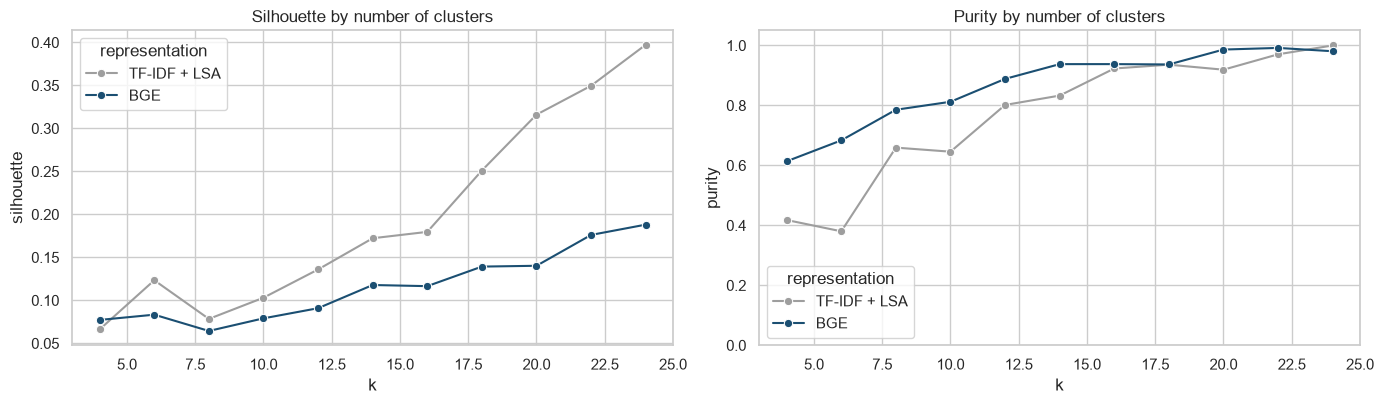

silhouette              purity             
representation        BGE TF-IDF + LSA    BGE TF-IDF + LSA
k                                                         
4                    0.08         0.07   0.61         0.42
6                    0.08         0.12   0.68         0.38
8                    0.06         0.08   0.79         0.66
10                   0.08         0.10   0.81         0.65
12                   0.09         0.14   0.89         0.80
14                   0.12         0.17   0.94         0.83
16                   0.12         0.18   0.94         0.92
18                   0.14         0.25   0.94         0.94
20                   0.14         0.32   0.99         0.92
22                   0.18         0.35   0.99         0.97
24                   0.19         0.40   0.98         1.00

In [3]:
def purity(labels):
    d = unique.assign(c=labels)
    return d.groupby("c").apply(lambda g: g.groupby(TARGET)["tickets"].sum().max() / g["tickets"].sum(), include_groups=False).mean()

rows = []
for name, E in [("TF-IDF + LSA", lsa), ("BGE", bge)]:
    for k in range(4, 25, 2):
        labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(E, sample_weight=unique["tickets"]).labels_
        rows.append({"representation": name, "k": k, "silhouette": silhouette_score(E, labels), "purity": purity(labels)})
scan = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axes, ["silhouette", "purity"]):
    sns.lineplot(data=scan, x="k", y=metric, hue="representation", marker="o", ax=ax, palette=["#9e9e9e", "#1b4f72"])
    ax.set_title(f"{metric.capitalize()} by number of clusters")
axes[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(FIG / "43_bge_global_clustering.png"); plt.show()
scan.pivot(index="k", columns="representation", values=["silhouette", "purity"]).round(2)

- **Purity: BGE wins at coarse levels.** With 8 clusters, 79% of a BGE cluster's tickets come from one category, vs 66% for LSA. With 4 clusters it's 61% vs 42%. Groups built on meaning line up with the support categories much better.
- **Silhouette: LSA wins**, rising to 0.40 at k = 24. LSA puts the 7 product versions of each template almost on top of each other (they share nearly every word), so around k = 24 each template becomes its own perfect cluster. BGE's high similarity floor gives lower silhouettes everywhere (0.06–0.19).
- Neither silhouette curve points to a natural number of groups across all categories, the same conclusion as notebook 04. We keep the within-category themes (section 4) as the main result, and use the cross-category clustering below for a different question.

## 3. A new view: product-area topics across categories

Because BGE also groups sentences by **what they are about**, clustering across categories gives a different, useful view.
We ask for 8 clusters (the same number as categories) and look at what ends up together.

In [4]:
K_TOPICS = 8
unique["topic"] = KMeans(n_clusters=K_TOPICS, n_init=20, random_state=SEED).fit(bge, sample_weight=unique["tickets"]).labels_
unique["product"] = product.fillna("(none)")

def top_terms(rows, n=4):
    # average TF-IDF of the sentences, weighted by ticket count (same as notebook 04)
    weights = unique.loc[rows, "tickets"].values[:, None]
    mean = np.asarray(tfidf_matrix[rows].multiply(weights).sum(axis=0)).ravel() / weights.sum()
    return ", ".join(terms[[j for j in np.argsort(-mean)[:n] if mean[j] > 0]])

topic_rows = []
for t, g in unique.groupby("topic"):
    by_cat = g.groupby(TARGET)["tickets"].sum().sort_values(ascending=False)
    by_prod = g.groupby("product")["tickets"].sum().sort_values(ascending=False)
    topic_rows.append({"topic": t, "top words": top_terms(g.index.values), "tickets": int(g["tickets"].sum()),
                       "categories": ", ".join(f"{c} {n / by_cat.sum():.0%}" for c, n in by_cat.head(4).items()),
                       "products": ", ".join(f"{p} {n / by_prod.sum():.0%}" for p, n in by_prod.head(3).items()),
                       "example": g.sort_values("tickets", ascending=False)[TEXT].iloc[0]})
topics = pd.DataFrame(topic_rows).sort_values("tickets", ascending=False).reset_index(drop=True)
topics

,topic,top words,tickets,categories,products,example
0,0,"export, data, section, export data",4886,"bug 39%, performance 29%, how_to 20%, security_concern 12%","data export 20%, notifications 18%, api integration 17%",I am seeing an error message when I click on notifications.
1,2,"team, option customize, customize, add",3690,"feature_request 68%, how_to 32%","api integration 16%, notifications 16%, analytics dashboard 16%",Can you add an option to customize analytics dashboard?
2,1,"login, says password, says, password incorrect",3460,"account_access 73%, bug 9%, performance 8%, how_to 7%","(none) 73%, login auth 27%",My account was locked after multiple failed login attempts.
3,5,"plan, twice, charged, charged twice",2992,"billing_problem 83%, bug 9%, security_concern 5%, how_to 4%","(none) 83%, billing 17%",I downgraded my plan but I am still being billed for the higher tier.
4,3,"account, question account, general, general question",2473,"other 66%, security_concern 34%",(none) 100%,I have a general question about my account.
5,7,"workspace, check workspace, check",848,other 100%,(none) 100%,"Something seems off, can you please check my workspace?"
6,6,"encryption compliance, data encryption, compliance, details",832,security_concern 100%,(none) 100%,We need details about your data encryption and compliance.
7,4,"overall performance, degraded days, degraded, days",819,performance 100%,(none) 100%,Overall performance has degraded in the last few days.


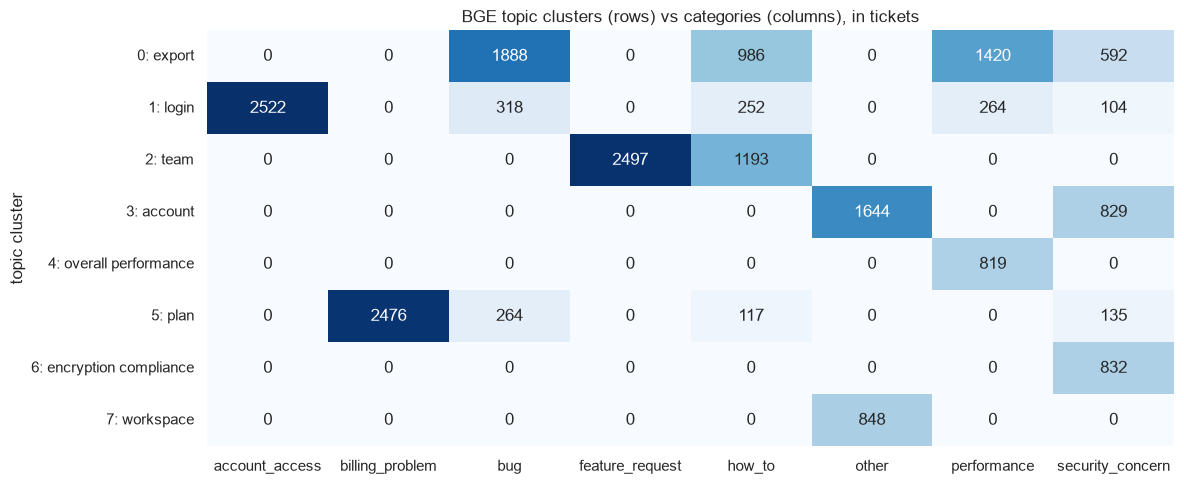

In [5]:
mix = unique.pivot_table(index="topic", columns=TARGET, values="tickets", aggfunc="sum", fill_value=0)
mix.index = [f"{t}: {topics.set_index('topic').loc[t, 'top words'].split(', ')[0]}" for t in mix.index]
plt.figure(figsize=(12, 5))
sns.heatmap(mix, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("BGE topic clusters (rows) vs categories (columns), in tickets"); plt.ylabel("topic cluster"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG / "44_bge_topics.png"); plt.show()

With 8 clusters, BGE groups tickets by **subject and intent**, not by category:

| Topic | What's in it | Tickets |
|---|---|---|
| **Something is broken** | bug, performance and vulnerability reports, plus "export my data" how-tos, mostly for products other than login | 4,886 |
| **Requests and set-up** | all feature requests plus "set up / configure" how-tos | 3,690 |
| **Login and sign-in** | all account_access tickets plus 8 of the 12 "login auth" sentences (crashes, slowness, set-up, vulnerability…) | 3,460 |
| **Billing and payments** | all billing_problem tickets plus 4 "billing" sentences (error, not saving, configure, vulnerability) | 2,992 |
| **Vague account questions** | the two general `other` sentences plus "I noticed a suspicious login on my account" | 2,473 |
| three single sentences | degraded performance, encryption and compliance, "check my workspace" | ~830 each |

**Why this is useful**
- **A subject-area view for teams.** The identity team would see 3,460 tickets about login, although only 2,522 are labelled account_access. The other 938 sit in bug, performance, how_to and security_concern. Billing is the same: 2,992 tickets vs 2,476 labelled billing_problem. Reporting by category alone hides this.
- **Only login and billing form areas of their own**, because those product names match the meaning of a whole category. The other five products stay spread over the "broken" and "requests" topics.
- It matches the classifier's remaining confusion in notebook 02b: `other` and security_concern sentences sit close together here.

## 4. Recurring themes within each category

Exactly the notebook 04 rule: for each category try k = 2 to 6, keep the k with the best silhouette, and if no k reaches 0.10, every sentence is its own theme.
We also measure how much the result agrees with notebook 04's themes (**adjusted Rand index**: 1 = identical grouping, 0 = no better than chance).

In [6]:
MIN_SILHOUETTE = 0.10
unique["cluster_id"] = ""
choices = []

for cat in sorted(unique[TARGET].unique()):
    idx = unique.index[unique[TARGET] == cat]
    E, w = bge[idx], unique.loc[idx, "tickets"]
    best = (None, -1, None)
    for k in range(2, min(6, len(idx) - 1) + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(E, sample_weight=w)
        s = silhouette_score(E, km.labels_)
        if s > best[1]:
            best = (k, s, km.labels_)
    if best[1] >= MIN_SILHOUETTE:
        labels, k_used = best[2], best[0]
    else:
        labels, k_used = np.arange(len(idx)), len(idx)          # every sentence is its own theme
    unique.loc[idx, "cluster_id"] = [f"{cat}#{l}" for l in labels]
    choices.append({"category": cat, "unique_sentences": len(idx), "themes (BGE)": k_used,
                    "themes (LSA, nb 04)": unique.loc[idx, "lsa_theme"].nunique(),
                    "best_silhouette": round(best[1], 2) if best[0] else None,
                    "agreement with nb 04 (ARI)": round(adjusted_rand_score(unique.loc[idx, "lsa_theme"], labels), 2)})

pd.DataFrame(choices)

,category,unique_sentences,themes (BGE),"themes (LSA, nb 04)",best_silhouette,agreement with nb 04 (ARI)
0,account_access,3,2,3,0.12,0.00
1,billing_problem,3,3,3,0.07,1.00
2,bug,21,3,3,0.27,1.00
3,feature_request,21,3,3,0.25,1.00
4,how_to,21,3,3,0.21,0.85
5,other,3,3,3,0.06,1.00
6,performance,15,3,3,0.28,1.00
7,security_concern,9,2,3,0.27,0.57


- **5 of 8 categories get exactly the same themes as notebook 04** (ARI 1.00): bug, feature_request, performance, billing_problem and other. For template-based categories, the problem wording dominates in both representations.
- Three categories change, and in each case the change follows meaning rather than shared words (details below).
- Silhouettes within categories are lower with BGE (0.21–0.28 vs 0.41–0.54 in notebook 04). That comes from BGE's similarity floor, not from worse themes: theme cohesion stays high (0.87–0.95, section 5).

In [7]:
# where the two methods disagree, show both groupings
for cat in [c["category"] for c in choices if c["agreement with nb 04 (ARI)"] < 1]:
    g = unique[unique[TARGET] == cat]
    print(f"\n=== {cat}")
    for name, col in [("LSA (notebook 04)", "lsa_theme"), ("BGE", "cluster_id")]:
        print(f"  {name}:")
        for _, grp in g.groupby(col):
            print("     -", " | ".join(grp[TEXT].str.slice(0, 60)))


=== account_access
  LSA (notebook 04):
     - I cannot log in; the system says my password is incorrect.
     - My 2FA code is not working when I try to sign in.
     - My account was locked after multiple failed login attempts.
  BGE:
     - My 2FA code is not working when I try to sign in.
     - I cannot log in; the system says my password is incorrect. | My account was locked after multiple failed login attempts.

=== how_to
  LSA (notebook 04):
     - How can I export my data from the analytics dashboard sectio | How can I export my data from the api integration section? | How can I export my data from the billing section? | How can I export my data from the data export section? | How can I export my data from the login auth section? | How can I export my data from the mobile app section? | How can I export my data from the notifications section?
     - I need help setting up analytics dashboard for my team. | I need help setting up api integration for my team. | I need help set

- **account_access:** BGE groups "I cannot log in; the system says my password is incorrect" with "My account was locked after multiple failed login attempts" (both are password / login failures) and keeps the 2FA problem separate. LSA couldn't group any of the three, because they share no words, so each one was its own theme.
- **security_concern:** BGE puts the vulnerability reports together with "suspicious login" (all possible security incidents) and keeps "encryption and compliance" (a request for information) apart. LSA left suspicious login on its own.
- **how_to:** "Can you explain how to configure data export properly?" moves from the "configure" theme to the "export my data" theme, because it is about data export. Here BGE groups by subject instead of question type. Either grouping is defensible.

## 5. Describe each theme

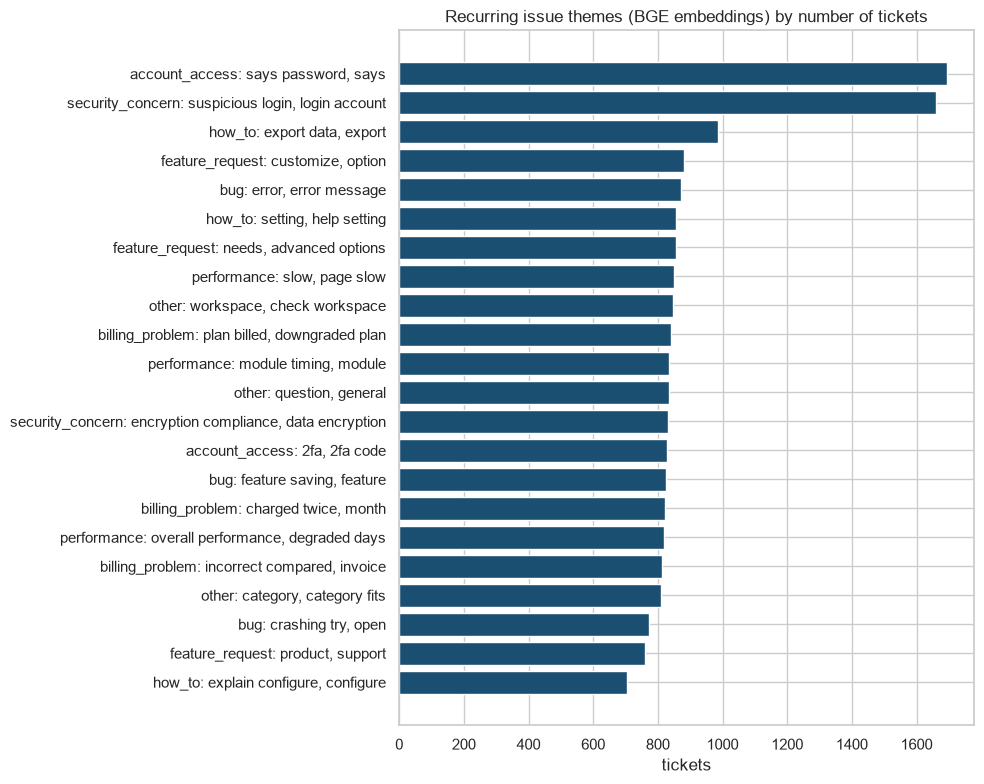

,category,theme,tickets,share_of_category,unique_sentences,cohesion,example
0,account_access,"says password, says, password, password incorrect",1693,0.67,2,0.95,My account was locked after multiple failed login attempts.
1,security_concern,"suspicious login, login account, noticed suspicious, suspicious",1660,0.67,8,0.90,I noticed a suspicious login on my account.
2,how_to,"export data, export, data, section",986,0.39,8,0.91,How can I export my data from the billing section?
3,feature_request,"customize, option, add, add option",880,0.35,7,0.89,Can you add an option to customize analytics dashboard?
4,bug,"error, error message, seeing, seeing error",871,0.35,7,0.91,I am seeing an error message when I click on notifications.
5,how_to,"setting, help setting, need help, help",856,0.34,7,0.90,I need help setting up login auth for my team.
6,feature_request,"needs, advanced options, advanced, team needs",856,0.34,7,0.92,Our team needs more advanced options for api integration.
7,performance,"slow, page slow, slow takes, takes",851,0.34,7,0.91,The login auth page is very slow and takes a long time to load.
8,other,"workspace, check workspace, check",848,0.34,1,1.00,"Something seems off, can you please check my workspace?"
9,billing_problem,"plan billed, downgraded plan, higher tier, higher",841,0.34,1,1.00,I downgraded my plan but I am still being billed for the higher tier.


In [8]:
summary = []
for cid, g in unique.groupby("cluster_id"):
    rows = g.index.values
    centre = bge[rows].mean(axis=0)
    summary.append({
        "cluster_id": cid,
        "category": g[TARGET].iloc[0],
        "theme": top_terms(rows),
        "tickets": int(g["tickets"].sum()),
        "unique_sentences": len(g),
        "cohesion": round(float((bge[rows] @ (centre / np.linalg.norm(centre))).mean()), 2),
        "example": g.sort_values("tickets", ascending=False)[TEXT].iloc[0],
    })
summary = pd.DataFrame(summary).sort_values("tickets", ascending=False).reset_index(drop=True)
summary["share_of_category"] = (summary["tickets"] / summary.groupby("category")["tickets"].transform("sum")).round(2)

plt.figure(figsize=(10, 8))
order = summary.sort_values("tickets")
plt.barh(order["category"] + ": " + order["theme"].str.split(", ").str[:2].str.join(", "), order["tickets"], color="#1b4f72")
plt.title("Recurring issue themes (BGE embeddings) by number of tickets"); plt.xlabel("tickets")
plt.tight_layout(); plt.savefig(FIG / "45_bge_themes.png"); plt.show()

summary[["category", "theme", "tickets", "share_of_category", "unique_sentences", "cohesion", "example"]]

**22 themes** (notebook 04 had 24). The two largest themes are now the merged ones:
- **login / password failures:** 1,693 tickets, 67% of account_access
- **security incidents** (vulnerabilities + suspicious login): 1,660 tickets, 67% of security_concern

In real data, these would be the first candidates for a permanent fix or a self-service article (for example, a better password-reset flow).

## 6. A 2-D map of the BGE embeddings

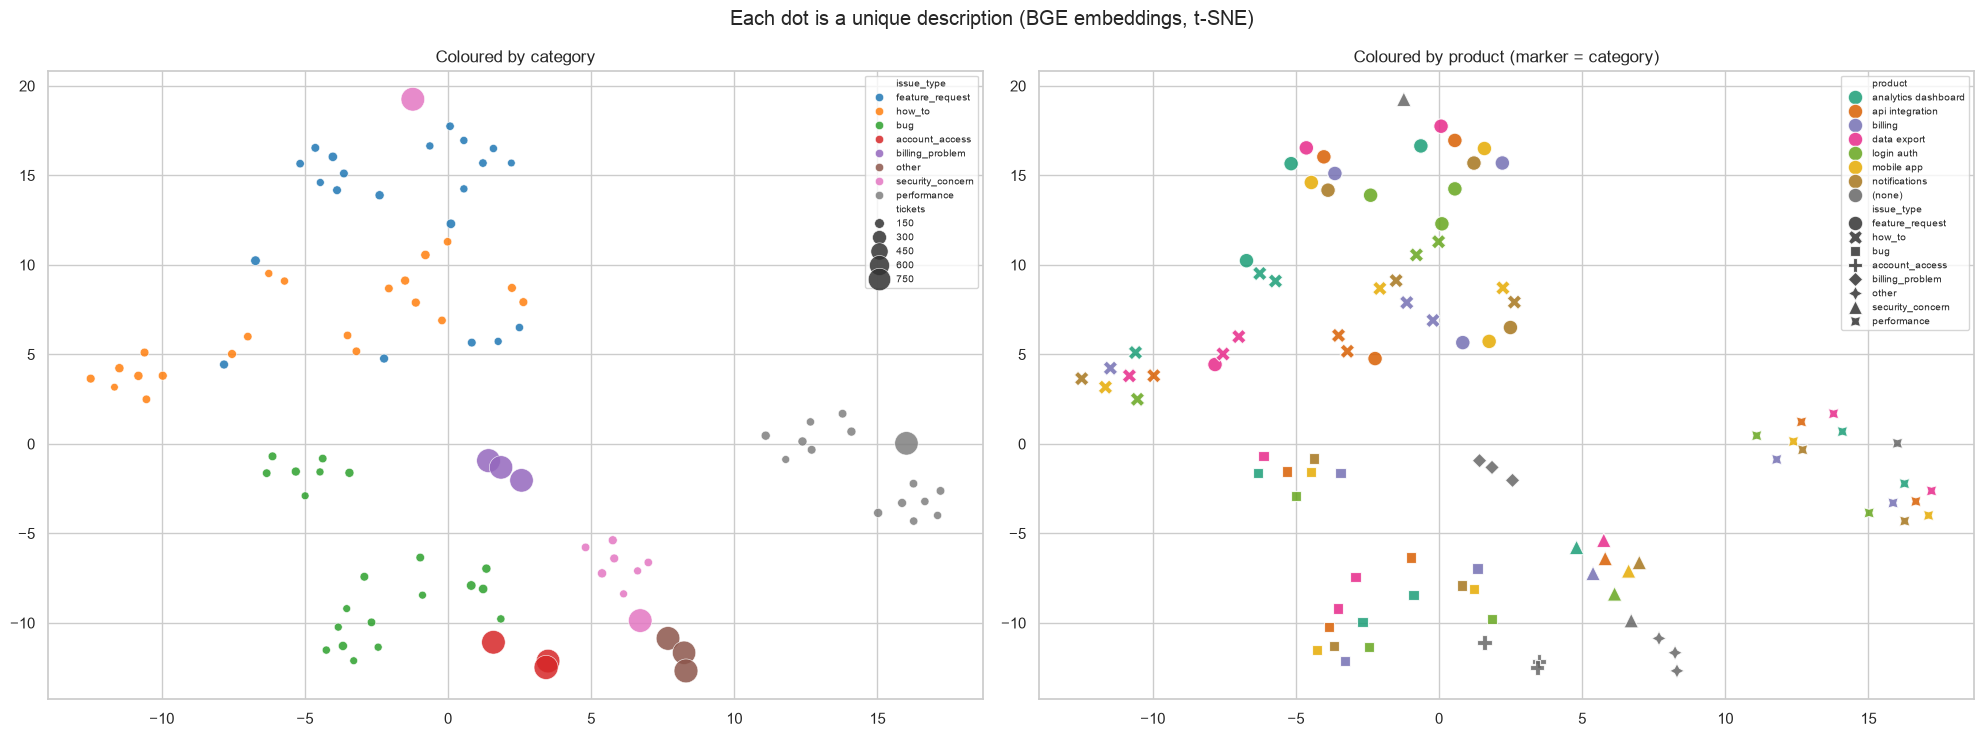

In [9]:
coords = TSNE(n_components=2, perplexity=10, random_state=SEED, init="pca").fit_transform(bge)
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=unique[TARGET], size=unique["tickets"], sizes=(30, 300),
                alpha=0.85, palette="tab10", ax=axes[0])
axes[0].set_title("Coloured by category")
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=unique["product"], style=unique[TARGET], s=110,
                alpha=0.85, palette="Dark2", ax=axes[1])
axes[1].set_title("Coloured by product (marker = category)")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel(""); ax.legend(bbox_to_anchor=(1, 1), fontsize=7)
plt.suptitle("Each dot is a unique description (BGE embeddings, t-SNE)")
plt.tight_layout(); plt.savefig(FIG / "46_bge_theme_map.png"); plt.show()

Categories form clear regions. feature_request and how_to sit next to each other (both are "asking for something"). bug, security_concern, account_access and other share the lower area (problem reports), and performance is its own island. In the right panel, the 7 product versions of each template stay close together, which matches the first table: the problem matters more than the product.

## 7. Save

In [10]:
clusters_bge = (tickets[["ticket_id", TEXT]]
                .merge(unique[[TEXT, "cluster_id", "topic"]], on=TEXT)
                .merge(summary[["cluster_id", "theme"]], on="cluster_id")
                .merge(topics[["topic", "top words"]].rename(columns={"top words": "topic_words"}), on="topic"))
clusters_bge[["ticket_id", "cluster_id", "theme", "topic", "topic_words"]].to_csv(config.PROCESSED / "clusters_bge.csv", index=False)
summary.to_csv(config.PROCESSED / "cluster_summary_bge.csv", index=False)
similarity.to_csv(config.PROCESSED / "clustering_similarity.csv")
scan.to_csv(config.PROCESSED / "clustering_bge_scan.csv", index=False)
pd.DataFrame(choices).to_csv(config.PROCESSED / "clustering_bge_vs_lsa.csv", index=False)
topics.to_csv(config.PROCESSED / "topic_clusters_bge.csv", index=False)
print("Saved clusters_bge.csv:", len(clusters_bge), "tickets | cluster_summary_bge.csv:", len(summary),
      "themes | topic_clusters_bge.csv:", len(topics), "topics")
print("Every ticket has a theme:", clusters_bge["ticket_id"].nunique() == len(tickets))

Saved clusters_bge.csv: 20000 tickets | cluster_summary_bge.csv: 22 themes | topic_clusters_bge.csv: 8 topics
Every ticket has a theme: True


## Summary

| | Notebook 04 (TF-IDF + LSA) | Notebook 4b (BGE) |
|---|---|---|
| What makes sentences similar | shared words | shared meaning, including the same subject (product) |
| Purity with 8 clusters across categories | 0.66 | **0.79** |
| Themes within categories | 24 | 22 |
| Same themes as notebook 04 | – | 5 of 8 categories identical |
| What changed | – | login / password failures merged; security incidents merged; "configure data export" joins the export theme |
| New view | – | 8 subject / intent topics; login area 3,460 tickets across 5 categories, billing area 2,992 |

- The recurring themes from notebook 04 are **confirmed** by a completely different representation, which makes them more trustworthy.
- Where BGE differs, it groups by meaning (login failures, security incidents), which LSA can't do when sentences share no words.
- The cross-category topic view is new: it shows subject areas, such as login and billing, that span several categories.
- The trend over time is not repeated here: the themes are nearly the same, and ticket volumes are flat (notebook 04, section 6).

**Saved:** `data/processed/clusters_bge.csv` (theme and topic for every ticket), `cluster_summary_bge.csv` (one row per theme), `topic_clusters_bge.csv` (one row per topic), `clustering_similarity.csv`, `clustering_bge_scan.csv`, `clustering_bge_vs_lsa.csv`, figures `43`–`46`. The dashboard still reads notebook 04's `clusters.csv`.